*<h1 align="center">$\textbf{Lab Report: ODE Initial Value Problem}$</h1>*

In [1]:
from google.colab import files

ModuleNotFoundError: No module named 'google.colab'

In [2]:
# Required packages
import numpy as np
import matplotlib.pyplot as plt

*<h3 align="center">$\textbf{Implementing the Leapfrog Method to solve an IVP}$</h3>*

## Electron plasma oscillation

An electron displaced from equilibrium in a uniform, fixed ion background feels an electric field proportional to its displacement, and oscillates at the plasma frequency $\omega_p$. In normalized units ($\omega_p = 1$), the motion is

$$\frac{dx}{dt} = v, \qquad \frac{dv}{dt} = -\omega_p^2\,x, \qquad \omega_p = 1$$

$$x(0) = 0.5, \qquad v(0) = 0, \qquad 0 \le t \le 20.$$

**Exact solution:**

$$x(t) = 0.5\cos t, \qquad v(t) = -0.5\sin t. $$

## Defining the leapfrog function

The motion is integrated with the second-order, symplectic leapfrog scheme, in which velocity and position are updated alternately at staggered times.

In [3]:

def leapfrog(x,v,h):
    x0=x
    v0=v
    a= -(Wp)**2*x
    v_new=v0 + h * a
    x_new=x0 + h * v_new

    return(x_new, v_new)

t=20 
h=0.1                                            ## Calculating for t=20
n=int(t/h)
p=[]
p.append(0.5)
q=[]
q.append(0)
x=0.5
vi=0
Wp=1
a= -(Wp)**2*x
v=vi - (0.5*h*a)

for i in range(0,n):
    s=leapfrog(x,v,h)
    p.append(s[0])
    q.append(s[1])
    x=s[0]
    v=s[1]

print(f"x_1={p[1]}")
print(f"v_1/2={q[1]}")




x_1=0.4975
v_1/2=-0.025


## Plotting the curves for the exact solution - to campare it with leapfrog values

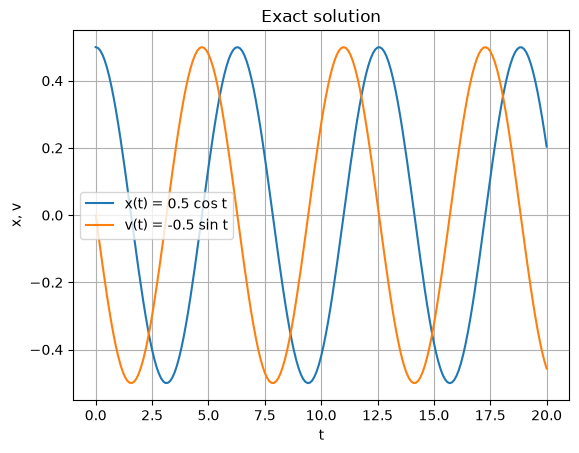

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# time values from 0 to 20 
t=np.arange(0, 20.1, 0.1)

# exact solution
x_exact = 0.5 * np.cos(t)
v_exact = -0.5 * np.sin(t)

# plot position and velocity against time
plt.plot(t, x_exact, label="x(t) = 0.5 cos t")
plt.plot(t, v_exact, label="v(t) = -0.5 sin t")
plt.xlabel("t")
plt.ylabel("x, v")
plt.title("Exact solution")
plt.legend()
plt.grid(True)
plt.show()

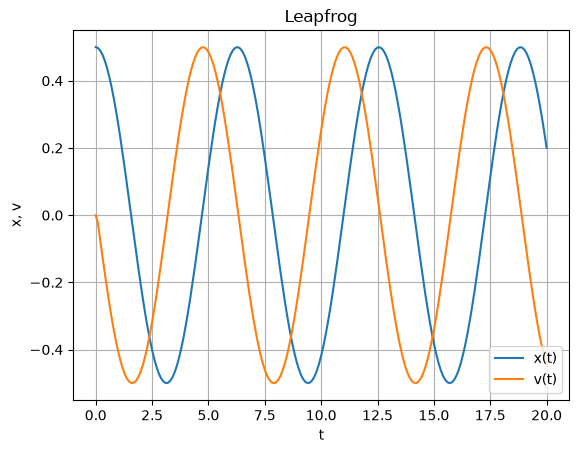

In [5]:
## Plotting the position and velocity curve for leapfrog function

plt.plot(t,p,label="x(t)")
plt.plot(t,q,label="v(t)")
plt.title("Leapfrog")
plt.xlabel("t")
plt.ylabel("x, v")
plt.grid()
plt.legend()
plt.show()

## Plotting the phase-space trajectory (x against v).

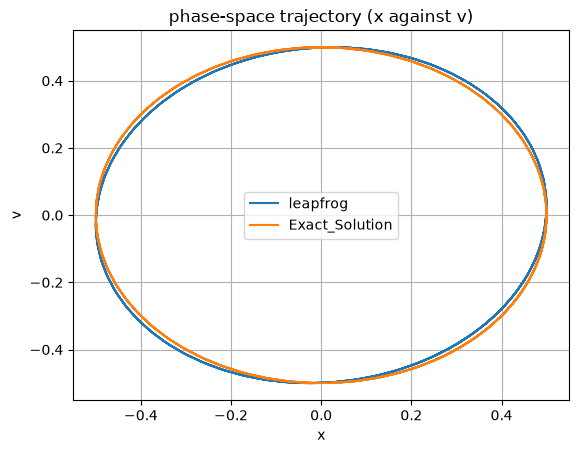

In [6]:
plt.plot(p,q,label="leapfrog")
plt.plot(x_exact,v_exact,label="Exact_Solution")
plt.xlabel("x")
plt.ylabel("v")
plt.title("phase-space trajectory (x against v)")
plt.legend()
plt.grid()
plt.show()

## Comparing the leapfrog curve with exact solution

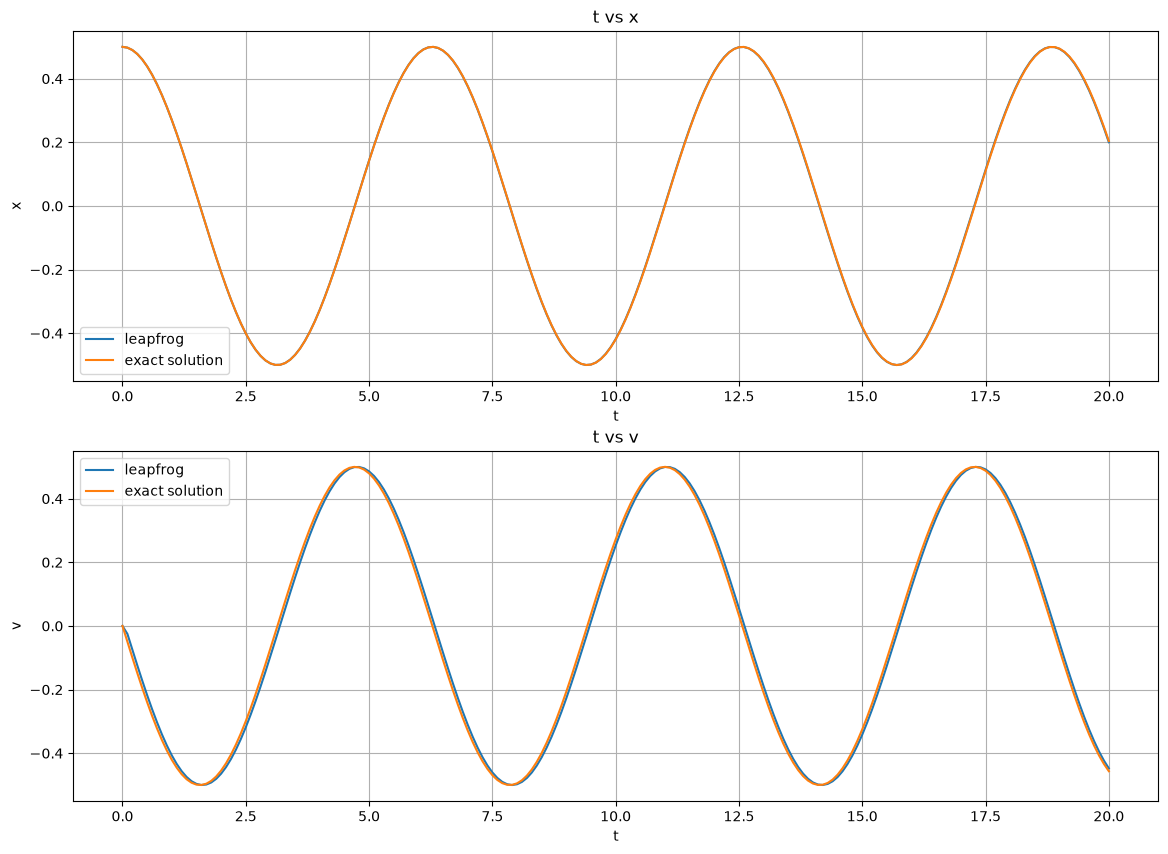

In [7]:
plt.figure(figsize=(14,10))
plt.subplot(2,1,1)
plt.plot(t,p,label="leapfrog")
plt.plot(t,x_exact,label="exact solution")
plt.title("t vs x")
plt.xlabel("t")
plt.ylabel("x")
plt.legend()
plt.grid()
plt.subplot(2,1,2)
plt.plot(t,q,label="leapfrog")
plt.plot(t,v_exact,label="exact solution")
plt.title("t vs v")
plt.xlabel("t")
plt.ylabel("v")
plt.legend()
plt.grid()
plt.show()

# Staggered 
### 2. Initialize the half step

Compute the staggered starting velocity from

$$v_{-1/2} = v_0 - \frac{h}{2}\,a(x_0), \qquad a(x) = -\omega_p^2\,x.$$

In [8]:
h=np.array([0.025,0.05,0.1,0.2])
w=len(h)
error_x=[]
error_v=[]
error_rms_x=[]
error_rms_v=[]

for i in range (0 , w):
    t=20
    h_new=h[i]
    n=int(t/h_new)
    x=0.5
    vi=0
    Wp=1
    a= -(Wp)**2*x
    v=vi - (0.5*h_new*a)
    p_new=[]
    q_new=[]
    p_new.append(x)
    q_new.append(vi)

    t=np.arange(0, 20+h_new, h_new)
    x_exact = 0.5 * np.cos(t)
    v_exact = -0.5 * np.sin(t)

    

    for j in range (0,n):
        s_new=leapfrog(x,v,h_new)
        p_new.append(s_new[0])
        q_new.append(s_new[1])
        x=s_new[0]
        v=s_new[1]

    x_diff= x_exact-p_new
    v_diff= v_exact-q_new
    
    max_error_x=np.max(abs(x_diff))         
    #print(f"max_error_x={max_error_x}")
    rms_error_x=np.sqrt(np.mean(x_diff**2))
    
    max_error_v=np.max(abs(v_diff))         
    #print(f"max_error_v={max_error_v}")
    rms_error_v=np.sqrt(np.mean(v_diff**2))
    
    
    error_x.append(max_error_x)
    error_v.append(max_error_v)
    error_rms_x.append(rms_error_x)
    error_rms_v.append(rms_error_v)


#print(error_x)
#print(error_v)
#print(error_rms_x)
#print(error_rms_v)
print(f"max_error_x={error_x}")

max_error_x=[np.float64(0.00023779054510253417), np.float64(0.0009516945580628489), np.float64(0.0038152808690173623), np.float64(0.015396153502616333)]


## Now comparing the max error and rms error
### Where we can see the rms error is very low compared to max error

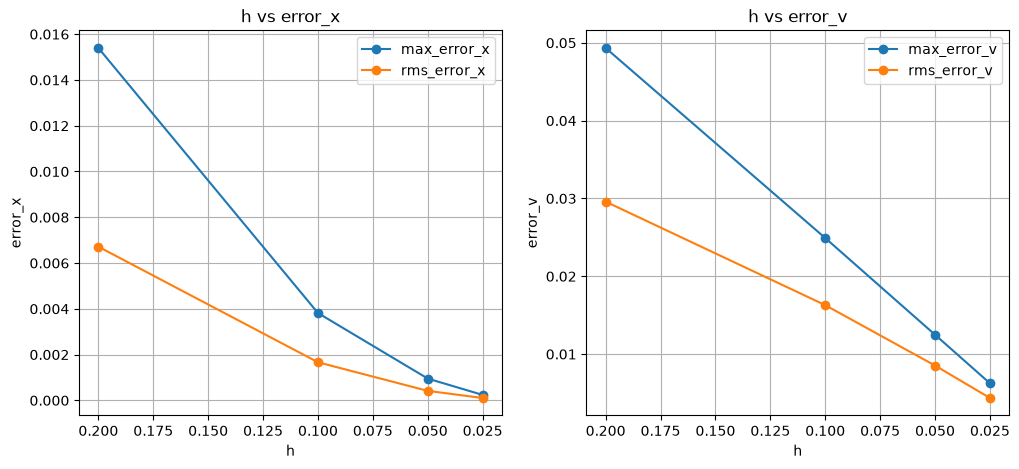

In [9]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(h,error_x,'-o',label="max_error_x")
plt.plot(h,error_rms_x,'-o', label="rms_error_x")
plt.gca().invert_xaxis()
plt.title("h vs error_x")
plt.xlabel("h")
plt.ylabel("error_x")
plt.legend()
plt.grid()

plt.subplot(1,2,2)
plt.plot(h,error_v,'-o',label="max_error_v")
plt.plot(h,error_rms_v,'-o', label="rms_error_v")
plt.gca().invert_xaxis()
plt.title("h vs error_v")
plt.xlabel("h")
plt.ylabel("error_v")
plt.legend()
plt.grid()
plt.show()

### Observed order of convergence

For a method of order $p$, the maximum error behaves as $e(h) \approx C\,h^p$. Halving the step size therefore gives

$$\frac{e(h)}{e(h/2)} = 2^p \quad\Longrightarrow\quad p = \log_2\!\left(\frac{e(h)}{e(h/2)}\right).$$


**Staggered start** ($v_{-1/2} = v_0 - \tfrac{h}{2}a(x_0)$): the error drops by a factor of about 4 each time $h$ is halved, so $p \approx 2$. This confirms that leapfrog is second-order accurate, in agreement with the central-difference result $x_{n+1} - 2x_n + x_{n-1} = -\omega_p^2 h^2 x_n$.


In [10]:
## Staggered P values


order=[]
for i in range(1, len(error_x)):
    ratio= (error_x[i]/error_x[i-1])
    order.append((np.log2(ratio)))

print("order_staggered =", [round(float(p), 3) for p in order])


order_staggered = [2.001, 2.003, 2.013]


**Result (staggered start):** the observed orders are $p = 2.001,\ 2.003,\ 2.013$ for the step pairs $(0.05, 0.025)$, $(0.1, 0.05)$ and $(0.2, 0.1)$. All are very close to 2, confirming that leapfrog with the staggered start is second-order accurate. The small excess above 2 at larger $h$ comes from the next-order error term, $O(h^4)$, which vanishes faster than the $h^2$ term as $h \to 0$.

## Repeating with the unstaggered start where  :  $ v_{-1/2} = v_{0}$

In [11]:
## unstaggered

h=np.array([0.025,0.05,0.1,0.2])
w=len(h)
error_x_us=[]
error_v_us=[]
error_rms_x_us=[]
error_rms_v_us=[]

for i in range (0 , w):
    t=20
    h_new=h[i]
    n=int(t/h_new)
    x=0.5
    vi=0
    Wp=1
    a= -(Wp)**2*x
    v=vi                              ## Unstagerred start
    p_new=[]
    q_new=[]
    p_new.append(x)
    q_new.append(vi)

    t=np.arange(0, 20+h_new, h_new)
    x_exact = 0.5 * np.cos(t)
    v_exact = -0.5 * np.sin(t)

    

    for j in range (0,n):
        s_new=leapfrog(x,v,h_new)
        p_new.append(s_new[0])
        q_new.append(s_new[1])
        x=s_new[0]
        v=s_new[1]

    x_diff= x_exact-p_new
    v_diff= v_exact-q_new
    
    max_error_x_us=np.max(abs(x_diff))         
    #print(f"max_error_x={max_error_x}")
    rms_error_x_us=np.sqrt(np.mean(x_diff**2))
    
    max_error_v_us=np.max(abs(v_diff))         
    #print(f"max_error_v={max_error_v}")
    rms_error_v_us=np.sqrt(np.mean(v_diff**2))
    
    
    error_x_us.append(max_error_x_us)
    error_v_us.append(max_error_v_us)
    error_rms_x_us.append(rms_error_x_us)
    error_rms_v_us.append(rms_error_v_us)


In [12]:
order_us=[]
for i in range(1, len(error_x)):
    ratio= (error_x_us[i]/error_x_us[i-1])
    order_us.append((np.log2(ratio)))

print("order_unstaggered =", [round(float(p), 3) for p in order_us])

order_unstaggered = [1.049, 1.095, 1.173]


**Result (unstaggered start):** the observed orders are $p = 1.049,\ 1.095,\ 1.173$. These are close to 1, so the order has dropped from 2 to about 1.

### Why does the order drop?

- Leapfrog needs the velocity at a **half step** before it starts. The correct value is

$$v_{-1/2} = v_0 - \frac{h}{2}\,a(x_0).$$

- In the unstaggered start, we skip the correction and use $v_{-1/2} = v_0$. The starting velocity is then wrong by $\frac{h}{2}\,a(x_0)$, which is proportional to $h$.
- This small mistake at the start is never corrected later. It stays in the solution as an error that is proportional to $h$.
- Leapfrog's own error is proportional to $h^2$. For small $h$, $h^2$ is much smaller than $h$, so the starting error is the bigger one and controls the result.
- When the error is proportional to $h$, halving $h$ only halves the error, so $p \approx 1$.
- For larger $h$, the $h^2$ part still adds a little, so $p$ is slightly above 1. It moves closer to 1 as $h$ gets smaller.

**Conclusion:** a second-order method gives second-order results only if it is started correctly. A first-order mistake at the start limits the whole solution to first-order accuracy.

### 5. Order of the method: elimination of $v$

**Leapfrog**

$$v_{n+\frac12} = v_{n-\frac12} + h\,a(x_n), \qquad a(x_n) = -\omega_p^2\,x_n \tag{1}$$

$$x_{n+1} = x_n + h\,v_{n+\frac12} \tag{2}$$

**Step 1: write for two consecutive steps**

From (2) at step $n$:

$$x_{n+1} - x_n = h\,v_{n+\frac12} \tag{3}$$

From (2) with $n \to n-1$:

$$x_n - x_{n-1} = h\,v_{n-\frac12} \tag{4}$$

**Step 2: subtract (4) from (3)**

$$x_{n+1} - 2x_n + x_{n-1} = h\left(v_{n+\frac12} - v_{n-\frac12}\right) \tag{5}$$

**Step 3: use the kick step to eliminate $v$**

From (1):

$$v_{n+\frac12} - v_{n-\frac12} = h\,a(x_n) = -\omega_p^2\,h\,x_n$$

Substituting into (5):

$$\boxed{x_{n+1} - 2x_n + x_{n-1} = -\,\omega_p^2\,h^2\,x_n}$$

This is the central difference formula for $\dfrac{d^2x}{dt^2} = -\omega_p^2 x$.



### 6. Stability limit of leapfrog: $\omega_p h < 2$

**Idea:** suppose the solution is multiplied by the same factor $r$ at every step. If $|r| = 1$ the size stays the same (stable). If $|r| > 1$ it grows at every step (unstable).

**Step 1: one equation.** Eliminating $v$ and writing $q = \omega_p h$:

$$x_{n+1} - (2 - q^2)\,x_n + x_{n-1} = 0$$

**Step 2: find $r$.** Put $x_n = r^n$ into the equation and divide by $r^{n-1}$:

$$r^2 - (2 - q^2)\,r + 1 = 0$$

**Step 3: key fact.** The two roots always satisfy

$$(r_+) \, (r_-) = 1.$$

Two numbers that multiply to 1 cannot both be smaller than 1 in size. So either both have size 1 (stable), or one is larger than 1 (unstable).

**Step 4: which case happens?** The roots are

$$r_{\pm} = 1 - \frac{q^2}{2} \pm \frac{q}{2}\sqrt{q^2-4}.$$

- **$q < 2$:** the square root is of a negative number, so the roots are complex. Since $r_+ r_- = 1$, both have $|r| = 1$. The solution oscillates with constant size, so the scheme is **stable**.
- **$q = 2$:** both roots equal $-1$ and the solution grows slowly (linearly), so the scheme is **marginally unstable**.
- **$q > 2$:** the roots are real and negative, and one of them has $|r| > 1$. The solution grows by that factor at every step, so the scheme is **unstable**.

**Conclusion:** leapfrog is stable only when

$$\boxed{\omega_p h < 2}$$

In words: the time step must be less than $2/\omega_p$. Since the oscillation period is $2\pi/\omega_p$, this means we need more than about 3 steps per oscillation.

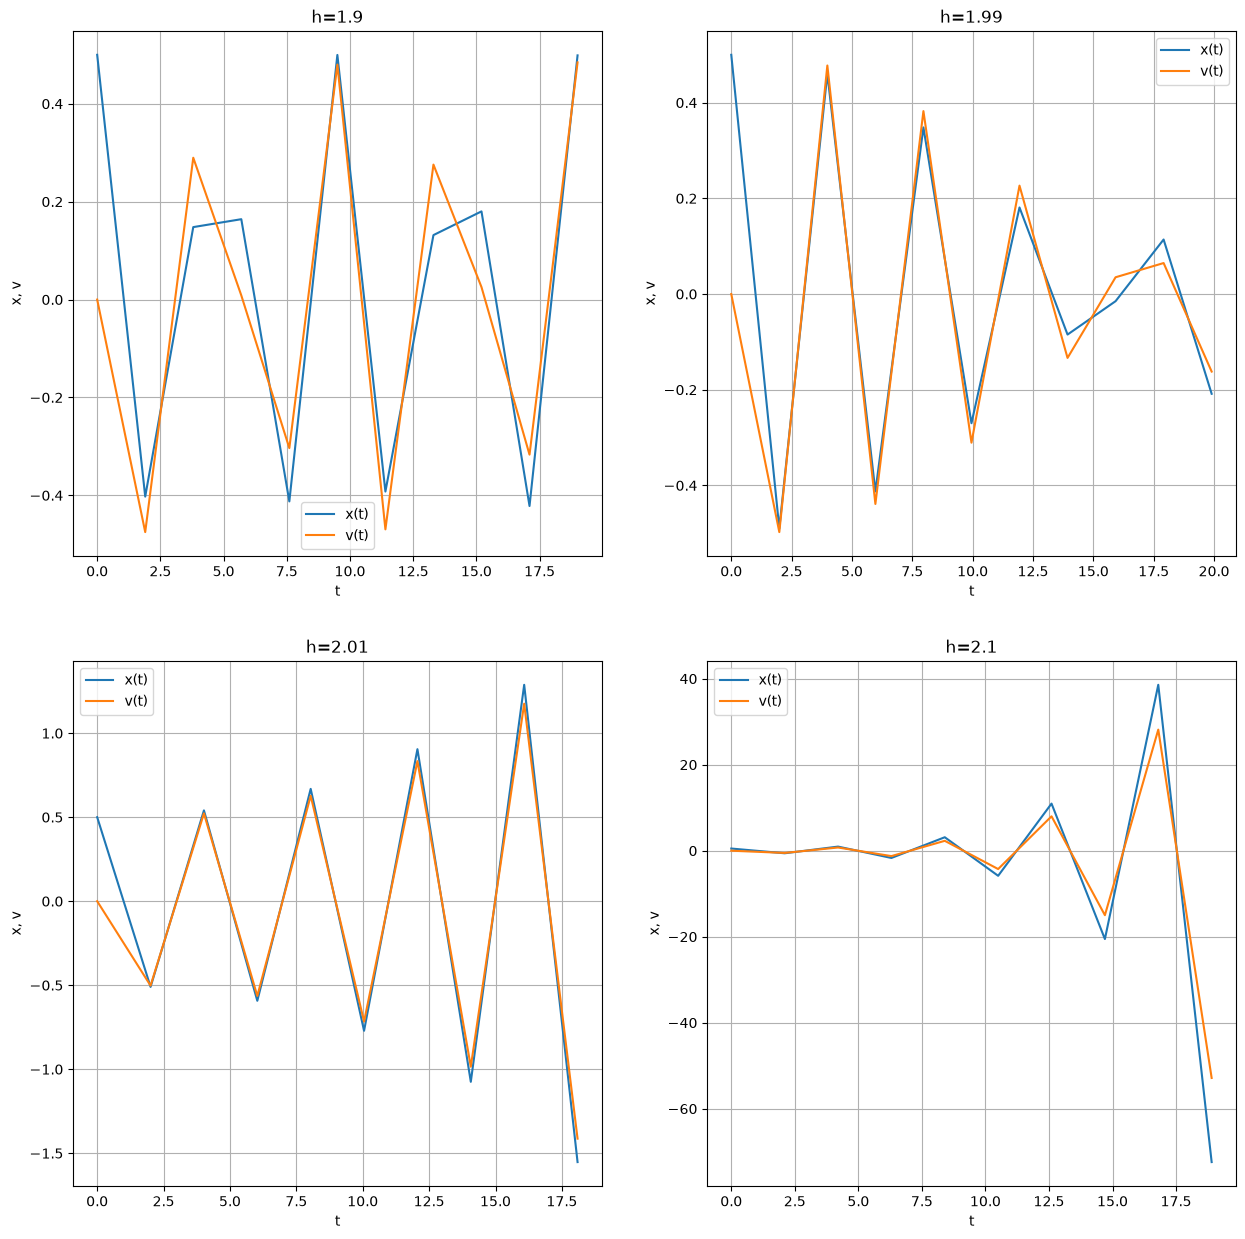

In [13]:

h=np.array([1.9,1.99,2.01,2.1])     
x=0.5
vi=0
Wp=1
a= -(Wp)**2*x
plt.figure(figsize=(15,15))
for j in range(0 , len(h)):
    x=0.5
    vi=0
    Wp=1
    a= -(Wp)**2*x
    n=int(20/h[j])
    p=[]
    p.append(0.5)
    q=[]
    q.append(0)
    t=np.arange(0, 20 , h[j])
    v=vi - (0.5*h[j]*a)
    
    for i in range(0,n):
        s=leapfrog(x,v,h[j])
        p.append(s[0])
        q.append(s[1])
        x=s[0]
        v=s[1]
    
    plt.subplot(2,2,(j+1))
    plt.plot(t,p,label="x(t)")
    plt.plot(t,q,label="v(t)")
    plt.title(f"h={h[j]}")
    plt.xlabel("t")
    plt.ylabel("x, v")
    plt.grid()
    plt.legend()
plt.show()


### Numerical confirmation of the stability limit

**Setup.** Leapfrog was run on $\dfrac{d^2x}{dt^2} = -\omega_p^2 x$ with $\omega_p = 1$, $x_0 = 0.5$, $v_0 = 0$, the staggered start $v_{-1/2} = v_0 - \frac{h}{2}a(x_0)$, and $0 \le t \le 20$, for four step sizes on either side of the limit $\omega_p h = 2$:

$$\omega_p h = 1.9,\quad 1.99,\quad 2.01,\quad 2.1$$

**Results.**

| $\omega_p h$ | behaviour |
|---|---|
| 1.9 | bounded |
| 1.99 | bounded |
| 2.01 | growing |
| 2.1 | growing rapidly |

**Observations.**

- For $\omega_p h = 1.9$ and $1.99$, $x$ keeps oscillating between $-0.5$ and $+0.5$ and never grows. 
- For $\omega_p h = 2.01$ and $2.1$, the amplitude grows at almost every step, and the sign alternates from step to step. This is the behaviour of a negative real root with $|r_-| > 1$.
- Crossing from $1.99$ to $2.01$ changes the behaviour from bounded to growing. This agrees with the analytical limit $\omega_p h < 2$.

**Why the growth looks mild for $\omega_p h = 2.01$.** The growth factor per step is $|r_-| = 1.221$. In only 9 steps the amplitude grows by about $1.221^9 \approx 6$, so the error is visible but small. For $\omega_p h = 2.1$ the factor is $1.877$ per step, which gives about $1.877^9 \approx 290$ in 9 steps. Over a longer run, both unstable cases would blow up completely. A step size just above 2 is a slow instability, but it is still an instability.

**Why the stable runs stay at exactly 0.5.** For $q < 2$ the roots are $e^{\pm i\theta}$, so the numerical solution is

$$x_n = 0.5\cos(n\theta), \qquad \cos\theta = 1 - \frac{q^2}{2},$$

which can never exceed $0.5$ in size. It oscillates with the correct amplitude, though at a wrong frequency $\theta/h \ne \omega_p$ when $h$ is large.

**Why every explicit PIC code must satisfy $\omega_p h < 2$.**

- The plasma oscillation at $\omega_p$ is the fastest natural motion in an electrostatic plasma, and an explicit leapfrog push is exactly the scheme tested above.
- If $\omega_p h > 2$, the oscillation cannot be resolved (fewer than about $\pi$ steps per period), and the numerical solution grows by a factor $|r_-| > 1$ at every step, so the simulation blows up.
- Stability is only the minimum condition. For accurate results, PIC codes use much smaller steps, typically $\omega_p h \lesssim 0.1$ to $0.2$.

**Conclusion.** The numerical experiment confirms the analytical result: leapfrog is stable for $\omega_p h < 2$ and unstable for $\omega_p h > 2$.

# Summary and conclusions

The electron plasma oscillation $\dot{x} = v,\ \dot{v} = -\omega_p^2 x$ with $\omega_p = 1$, $x(0) = 0.5$, $v(0) = 0$ was integrated over $0 \le t \le 20$ using the leapfrog (kick-drift) scheme and compared with the exact solution $x(t) = 0.5\cos t$, $v(t) = -0.5\sin t$.

**Main findings**

1. **Accuracy.** With the staggered start $v_{-1/2} = v_0 - \frac{h}{2}a(x_0)$, the numerical solution follows the exact one closely. The maximum error in $x$ was about $2.4\times10^{-4}$ for $h = 0.025$ and $1.5\times10^{-2}$ for $h = 0.2$.

2. **Order of the method.** Eliminating $v$ shows that leapfrog is the central difference formula
$$x_{n+1} - 2x_n + x_{n-1} = -\omega_p^2 h^2 x_n,$$
whose truncation error is $O(h^2)$. The convergence study confirms this: the observed order is $p = 2.001,\ 2.003,\ 2.013$, so halving $h$ reduces the error by a factor of about 4.

3. **Effect of the starting velocity.** With the unstaggered start $v_{-1/2} = v_0$, the observed order drops to $p = 1.049,\ 1.095,\ 1.173$, which is close to 1. The starting velocity is then wrong by $\frac{h}{2}a(x_0) = O(h)$, and this first-order error is never removed later. For small $h$ it is larger than leapfrog's own $O(h^2)$ error, so it limits the whole solution to first order.

4. **Stability.** The characteristic equation $r^2 - (2 - q^2)r + 1 = 0$, with $q = \omega_p h$, has roots with $r_+ r_- = 1$. For $q < 2$ the roots are complex with $|r| = 1$, so the solution stays bounded. For $q > 2$ one root has $|r| > 1$, so the solution grows at every step. The runs with $\omega_p h = 1.9$ and $1.99$ stayed bounded, while $2.01$ and $2.1$ grew, which confirms the limit
$$\omega_p h < 2.$$

**Conclusions**

- Leapfrog is second-order accurate, but only when the half-step start is consistent with the scheme.
- It is stable only for $\omega_p h < 2$, which means more than about $\pi$ steps per plasma period.
- Every explicit PIC code uses leapfrog to push particles, so it must satisfy this limit, using the highest plasma frequency in the simulation. In practice, accuracy needs a much smaller step (typically $\omega_p h \lesssim 0.1$ to $0.2$), so stability is only the minimum requirement.
- Leapfrog is cheap (one acceleration evaluation per step), time-reversible and symplectic, which is why it is the standard choice for long plasma and orbit simulations.